# Learning a DES-footprint map generator from Rafael's simulations

This notebook accompanies [the teaching note](gptg_simulations.pdf). We implement the point-transformed Gaussian method of [Kunhao Zhong and coauthors](https://arxiv.org/abs/2411.04759), fit an initial model to 32 supplied maps, save 64 new four-bin maps with Gaussian shape noise, and measure second- and third-order apertures. **This pilot is not a validated DES covariance model.**

**Thanks to Kunhao Zhong and coauthors for the method, Rafael Gomes for the simulation maps, and the ducc0/HEALPix developers for the transforms and geometry.** This is our implementation and fit, not a supplied author calibration.

The default cells use compact records committed under `tests/gptg_pilot/`. They do not process the full archive. Optional generation and measurement commands appear at the end. Raw generated maps stay under the ignored `chains/gptg_method/maps/` directory.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import os
# Set these before importing numerical libraries. ducc0 separately gets
# nthreads=4 in the map script; BLAS never gets four workers.
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['OMP_NUM_THREADS'] = '4'
from pathlib import Path
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
import yaml
from IPython.display import Image, display

# Find this project whether Jupyter starts here or at the project root.
PROJECT = Path.cwd().resolve()
while not (PROJECT / 'EXAMPLE_COVARIANCE_PME.ipynb').exists():
    if PROJECT == PROJECT.parent:
        raise FileNotFoundError('Start this notebook within projects/des_3pcf.')
    PROJECT = PROJECT.parent
NOTE = PROJECT / 'notes' / 'gptg_simulations'
RECORDS = PROJECT / 'tests' / 'gptg_pilot'
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams["figure.dpi"] = 90


## 1. Inspect the calibration before using it

The transform acts on **convergence**, not separately on the two shear components. Our available input maps contain shear. We therefore fit a *masked, smoothed, noisy reconstruction proxy* as an initial approximation. This distinction is one reason a small quantile-fit residual does not validate the resulting sky model.

Read the recorded input selection, noise amplitudes and transformation family. The bin-two fit uses the paper's four-parameter restriction because an unrestricted initial fit turned over in a tail. Parameters near their fitting bounds also deserve attention.

In [2]:
calibration = yaml.safe_load((RECORDS / 'calibration.yaml').read_text())
generation = yaml.safe_load((RECORDS / 'generation.yaml').read_text())
print('Calibration maps:', len(calibration['source_files']))
print('Generated maps:', generation['count'])
print('NSIDE and maximum multipole:', calibration['nside'], calibration['lmax'])
print('Per-component pixel noise:', calibration['noise_sigma_per_component'])
for source, family in enumerate(calibration['fitted_family'], start=1):
    print('Source', source, ':', family)
print('Parameters are a1, a2, b, x0, t:')
print(np.asarray(calibration['point_parameters_a1_a2_b_x0_t']))

Calibration maps: 32
Generated maps: 64
NSIDE and maximum multipole: 512 1024
Per-component pixel noise: [0.03544957212835064, 0.03845571849948187, 0.038129787831707534, 0.04684877382544602]
Source 1 : five-parameter
Source 2 : four-parameter; b fixed to zero for global monotonicity
Source 3 : five-parameter
Source 4 : five-parameter
Parameters are a1, a2, b, x0, t:
[[ 2.37551585e-01  2.13293612e-01  9.99996434e-01  1.25883628e+00
   4.00000000e+00]
 [ 2.68977167e-02  5.00000002e-03  0.00000000e+00  2.76947383e+00
   4.81012632e-01]
 [ 1.31889354e-02  1.26374845e-02  2.60573386e-06  1.26083202e+00
   4.00000000e+00]
 [ 2.19034250e-01  1.95423544e-01  1.00000000e+00 -3.00000000e+00
   2.00000000e-01]]


## 2. Why a nonlinear point transform also changes correlations

Take two unit Gaussian variables with correlation $\rho$. For a simple centered lognormal transform, define

$$f_i(g)=e^{a_i g-a_i^2/2}-1.$$

The Gaussian exponential identity gives

$$\mathbb E[e^{a_i g_1+a_j g_2}]
=\exp\left[\frac12(a_i^2+a_j^2+2a_ia_j\rho)\right].$$

Multiplying by the two normalization factors cancels $a_i^2/2$ and $a_j^2/2$, leaving $e^{a_ia_j\rho}$. Expanding the product of the two centered transforms then gives

$$\mathbb E[f_i(g_1)f_j(g_2)]
=e^{a_ia_j\rho}-1-1+1=e^{a_ia_j\rho}-1.$$

Thus a desired output correlation is generally **not** the Gaussian input correlation. For the more flexible fitted function, the code evaluates and inverts this relation numerically through Hermite coefficients. The note derives each step. The small example below shows the change even in the simpler analytic case.

In [3]:
a = 0.5
rho = 0.6
# Divide by the lognormal variance to obtain its correlation coefficient.
output_correlation = np.expm1(a*a*rho) / np.expm1(a*a)
# Invert the same relation, recovering the required Gaussian correlation.
recovered = np.log1p(output_correlation*np.expm1(a*a)) / (a*a)
print('Gaussian correlation:', rho)
print('Transformed correlation:', output_correlation)
np.testing.assert_allclose(recovered, rho, atol=1.e-14)
print('Inversion recovers:', recovered)

Gaussian correlation: 0.6
Transformed correlation: 0.5697878894627386
Inversion recovers: 0.6000000000000001


## 3. A footprint index is a sky address

A saved map has shape `(4, 2, 369190)`: four source bins, two shear components and retained pixels. Entry `map[i,c,j]` belongs to full-sky pixel `indices_512[j]`. The last axis is not a rectangular image.

The pilot uses the RING ordering supported by the earlier geometric footprint check. A second-component sign diagnostic favors the current convention, but producer confirmation is still needed for sign-sensitive third moments. Generating convergence on the sphere, converting it to shear, and only then selecting footprint pixels retains the intended large-scale spatial correlations.

In [4]:
number_of_pixels = generation['shape'][-1]
bytes_per_map = 4 * 2 * number_of_pixels * 8  # float64 payload
print('Payload per map [MB]:', bytes_per_map/1.e6)
print('64-map payload [GB]:', 64*bytes_per_map/1.e9)
print('10000-map payload [GB]:', 10000*bytes_per_map/1.e9)
timing = np.loadtxt(fname=RECORDS / 'generation_timing.txt')
print('Median generation/save/aperture seconds:', np.median(timing, axis=0))
print('Median total seconds:', np.median(timing.sum(axis=1)))

Payload per map [MB]: 23.62816
64-map payload [GB]: 1.51220224
10000-map payload [GB]: 236.2816
Median generation/save/aperture seconds: [4.25585071e+00 4.22324997e-03 6.79079152e-03]
Median total seconds: 4.267709020990878


## 4. Correct a noisy aperture square and cube

A filtered aperture is $A=s+n$, where $s$ is fixed while we average over noise. Assume $\mathbb E[n]=0$, $\mathbb E[n^2]=v$ and zero third noise moment. Expanding the square gives

$$A^2=s^2+2sn+n^2.$$

Averaging each term gives

$$\mathbb E[A^2\mid s]=s^2+2s(0)+v=s^2+v.$$

Subtract the known variance:

$$\mathbb E[A^2-v\mid s]=s^2.$$

For the cube, multiply the three factors before averaging:

$$A^3=s^3+3s^2n+3sn^2+n^3.$$

Therefore

$$\mathbb E[A^3\mid s]=s^3+3s^2(0)+3sv+0=s^3+3sv.$$

The signal is unknown, but $\mathbb E[A\mid s]=s$. Multiplying that identity by $3v$ and subtracting yields

$$\mathbb E[A^3-3vA\mid s]=s^3+3sv-3vs=s^3.$$

**This aperture correction is different from correcting the square of a noisy covariance matrix in Eifler's expansion.** Neither operation removes the random scatter of a noisy observation.

In [5]:
from scipy.special import roots_hermitenorm

# Gaussian quadrature integrates the low-degree polynomial exactly,
# making a coefficient/sign mistake visible without Monte Carlo noise.
nodes, weights = roots_hermitenorm(n=12)
weights = weights / np.sqrt(2*np.pi)
signal = 0.2
noise_variance = 0.07
aperture = signal + np.sqrt(noise_variance)*nodes
raw_second = weights @ aperture**2
corrected_second = weights @ (aperture**2-noise_variance)
raw_third = weights @ aperture**3
corrected_third = weights @ (aperture**3-3*noise_variance*aperture)
print('Square: raw, corrected, target:', raw_second, corrected_second, signal**2)
print('Cube: raw, corrected, target:', raw_third, corrected_third, signal**3)
np.testing.assert_allclose(corrected_second, signal**2, atol=1.e-14)
np.testing.assert_allclose(corrected_third, signal**3, atol=1.e-14)

Square: raw, corrected, target: 0.11000000000000001 0.04000000000000002 0.04000000000000001
Cube: raw, corrected, target: 0.05000000000000002 0.008000000000000007 0.008000000000000002


## 5. Carry the correction to mixed source bins

There are three ways to pair two noise factors in a cubic product. If $V_{ij}$ is their covariance, the corrected product is

$$T_{ijk}=A_iA_jA_k-V_{ij}A_k-V_{ik}A_j-V_{jk}A_i.$$

The note expands all eight terms of the original product and cancels the three extra expectations. In our initial model, different source bins have independent noise. For `(1,1,2)`, only $V_{11}A_2$ remains; for `(1,2,3)`, no pair subtraction remains. The same-bin case has all three pairings and reduces to the factor of three above.

The filter noise is calculated from **squared pixel weights**, not fitted from the measured cube. We retain one variance per source, radius and center. The next cells inspect the resulting raw/corrected measurements for all 60 tomographic rows. For Rafael's maps, the assumed pixel-noise prescription is approximate; these corrections do not establish his actual estimator.

In [6]:
rows = np.loadtxt(fname=RECORDS / 'tomographic_rows.txt', dtype=int)
raw = np.loadtxt(fname=RECORDS / 'generated_tomographic_raw.txt')
corrected = np.loadtxt(fname=RECORDS / 'generated_tomographic_corrected.txt')
filter_variance = np.loadtxt(fname=RECORDS / 'aperture_noise_variance.txt')
print('Rows: order, radius, source i, source j, source k:')
print(rows[:3])
print('Maps by measurements:', raw.shape)
print('Filter-noise rows by centers:', filter_variance.shape)
# Row 10 is the first cubic row: source 1 three times, at 30 arcminutes.
row = 10
print('Selected cubic row:', rows[row])
print('Mean raw cube:', raw[:, row].mean())
print('Mean corrected cube:', corrected[:, row].mean())
# Distinct bins have no correction under the stipulated noise model.
distinct = (rows[:,0] == 3) & (rows[:,2] < rows[:,3]) & (rows[:,3] < rows[:,4])
np.testing.assert_array_equal(raw[:, distinct], corrected[:, distinct])

Rows: order, radius, source i, source j, source k:
[[ 2 30  1  1  0]
 [ 2 30  1  2  0]
 [ 2 30  1  3  0]]
Maps by measurements: (64, 60)
Filter-noise rows by centers: (8, 64)
Selected cubic row: [ 3 30  1  1  1]
Mean raw cube: 4.1467049172298355e-10
Mean corrected cube: 3.630943045092821e-10


## 6. Test the maps after all transformations

Fitting the central proxy quantiles is only a starting step. We must remeasure spectra, distributions, means and covariance after applying the same footprint, noise and measurement. The figures below come from the saved measurements, and their adjacent plot scripts redraw from text alone.

The spectra compare 64 generated maps with the 32 calibration maps. The covariance comparison uses the same **16 raw same-source moments** as the complete 15,997-vector Rafael diagnostic. It does not silently switch to the 60 corrected rows. The starting fit reused part of the reference ensemble, so these are consistency diagnostics, not independent validation p-values.

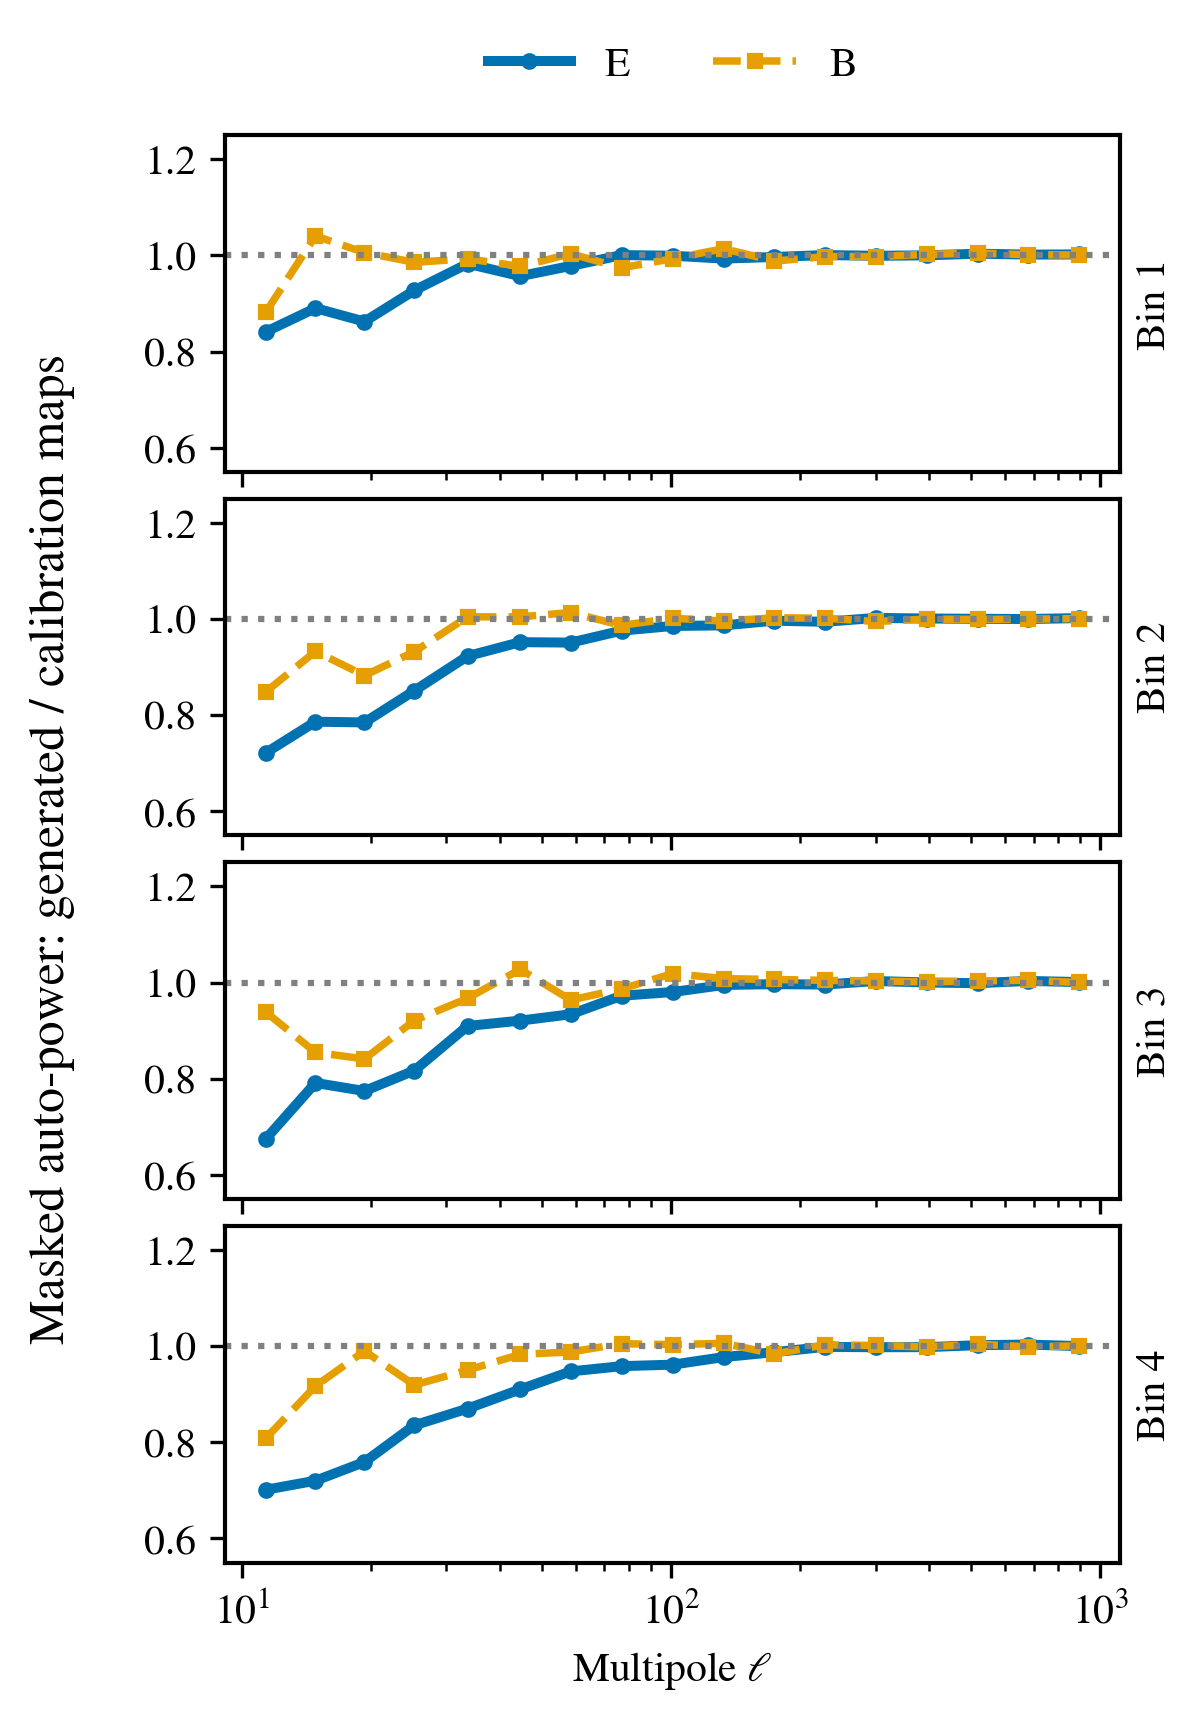

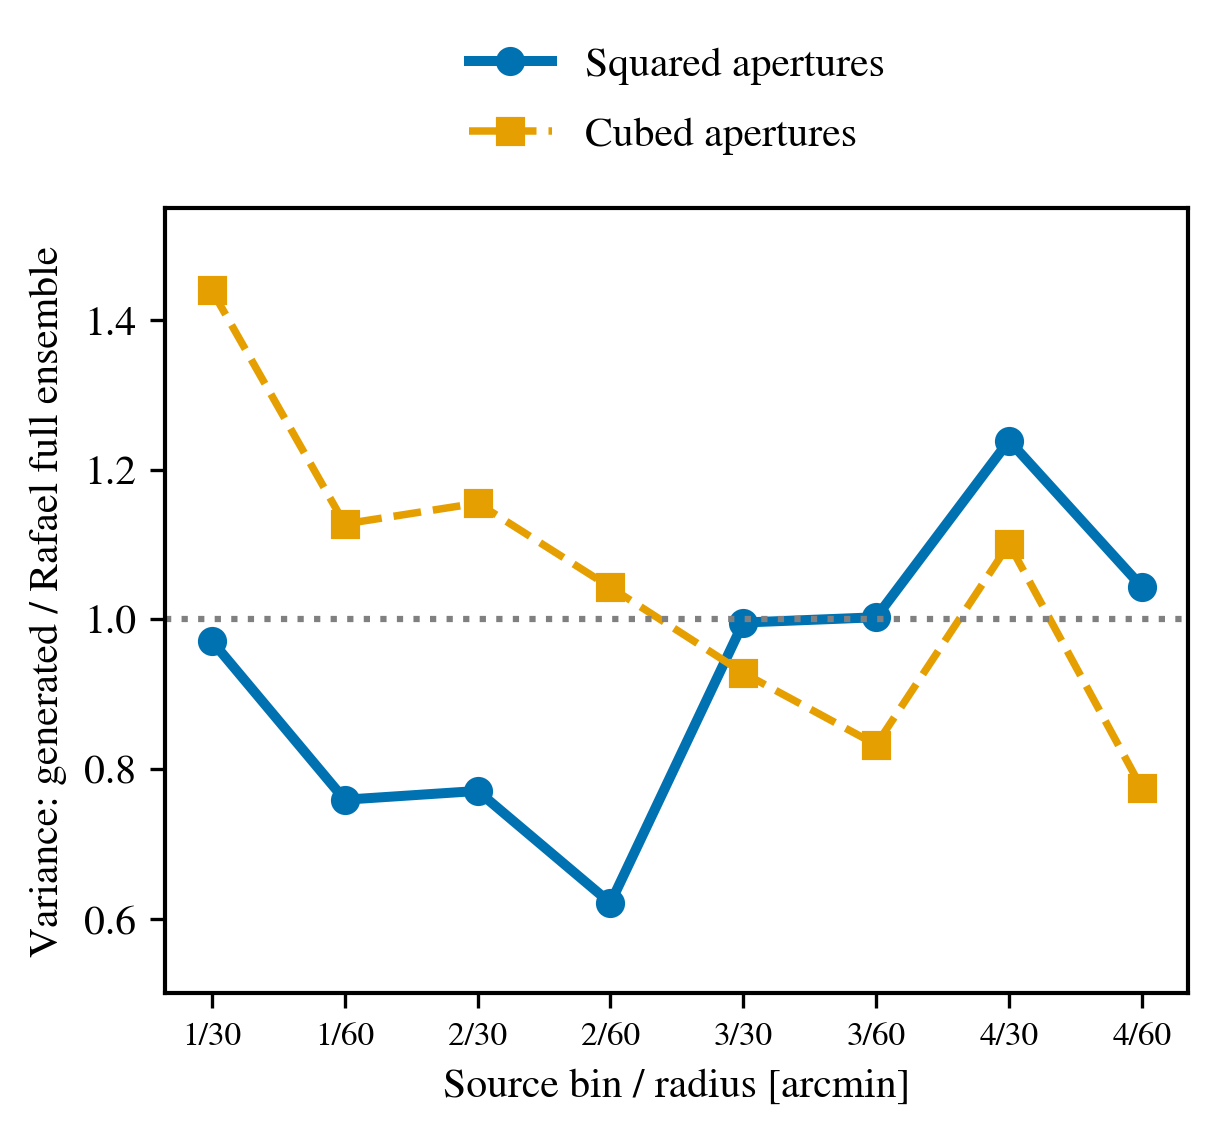

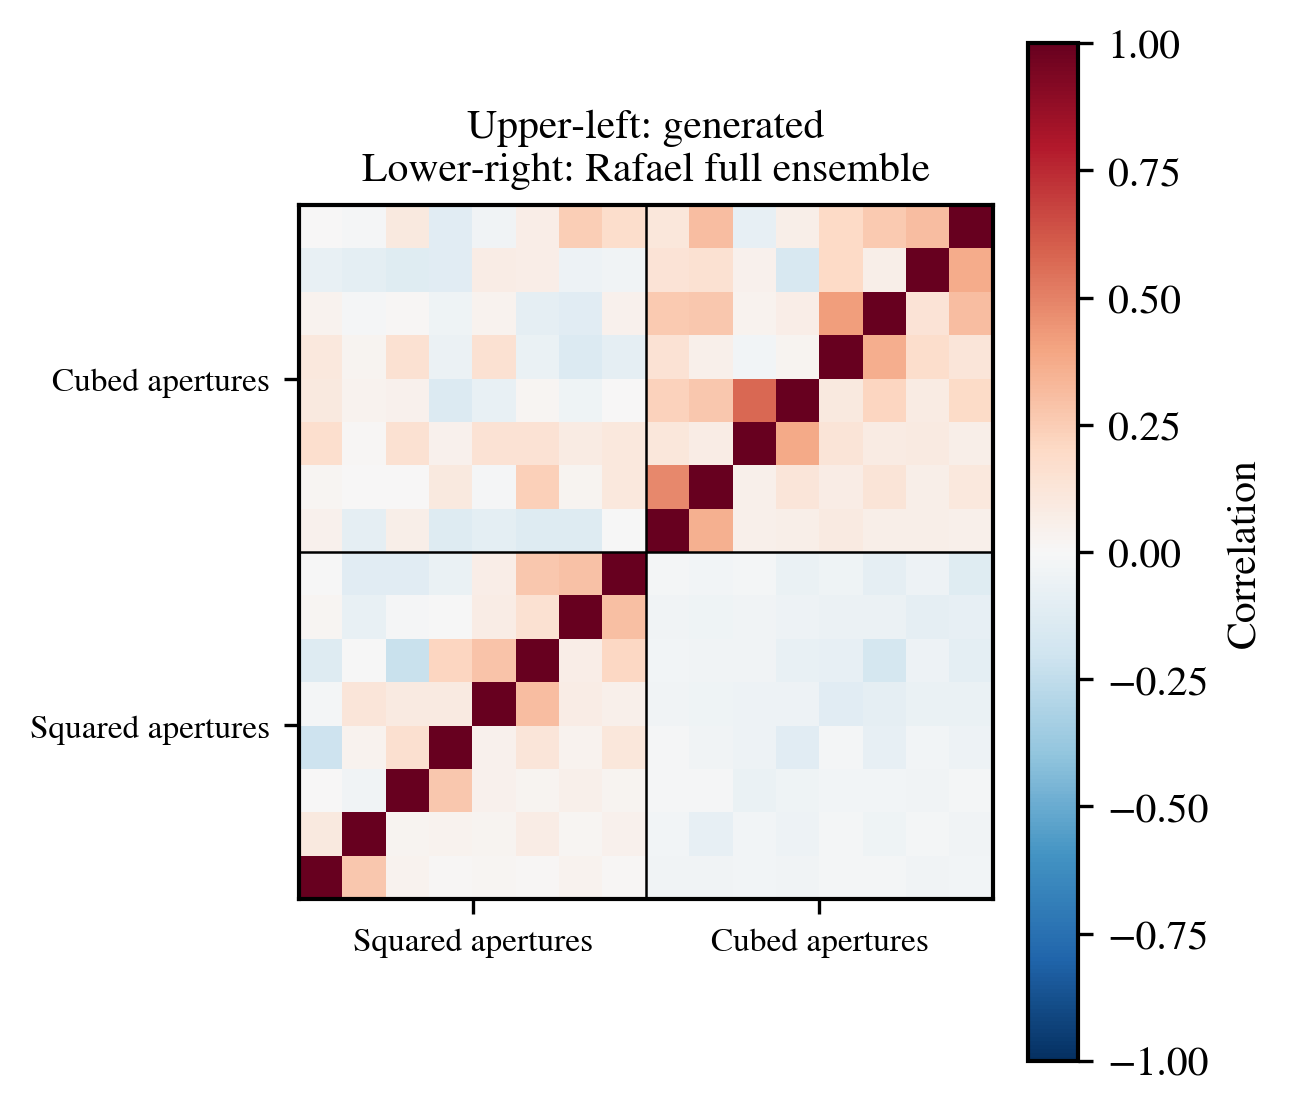

Variance-ratio range: 0.6207341560973392 1.4397128153454377
Largest absolute correlation difference: 0.332108476048442
Gaussian benchmark for 64-map variance scatter: 0.1781741612749496


In [7]:
for figure in ('spectra', 'variance', 'correlation'):
    display(Image(filename=str(NOTE / 'plots' / figure / f'{figure}.png'), width=650))

reference = np.loadtxt(
    fname=PROJECT / 'tests/covariance_map_comparison/all_maps_covariance.txt',
)
generated = np.loadtxt(fname=RECORDS / 'generated_covariance.txt')
ratio = np.diag(generated)/np.diag(reference)
reference_scale = np.sqrt(np.diag(reference))
generated_scale = np.sqrt(np.diag(generated))
reference_correlation = reference/reference_scale[:,None]/reference_scale[None,:]
generated_correlation = generated/generated_scale[:,None]/generated_scale[None,:]
print('Variance-ratio range:', ratio.min(), ratio.max())
print('Largest absolute correlation difference:',
      np.max(np.abs(generated_correlation-reference_correlation)))
print('Gaussian benchmark for 64-map variance scatter:', np.sqrt(2/63))

## 7. What sixth order does on a measured-vector population

We need known truth to test algebra. The continuous map model does not provide an exact covariance for these measured statistics. Instead, define a discrete population consisting of all 64 saved vectors, each with probability $1/64$. Select four joint second-/third-order rows. Its covariance uses denominator **64**, because the list defines the whole population. Covariances estimated from independent samples drawn from it use **$N-1$**.

Each experiment chooses 128 or 512 list members independently *with replacement*. We repeated this 8,192 times. These are independent experiments conditional on the list, **not new independent physical skies**. A fixed positive reference is chosen before resampling. The error compares estimated precision with the exact inverse of this specified population covariance.

The distinct-pair method needs independence and suitable finite moments, but not a Gaussian distribution. The Wishart formulas are tested deliberately even though these measurements are not Gaussian. Unbiasedness for a truncated polynomial does not imply unbiasedness for the full inverse or its inverse covariance.

Exactly defined discrete-population covariance:
[[ 1.          0.0201648   0.0467967  -0.07676721]
 [ 0.0201648   1.         -0.12952458 -0.04906478]
 [ 0.0467967  -0.12952458  1.          0.13601114]
 [-0.07676721 -0.04906478  0.13601114  1.        ]]
128 draws, distinct-pair RMS at orders 2,4,6: [0.19427558 0.22626533 0.26736764]
512 draws, distinct-pair RMS at orders 2,4,6: [0.15818393 0.11648588 0.13001479]


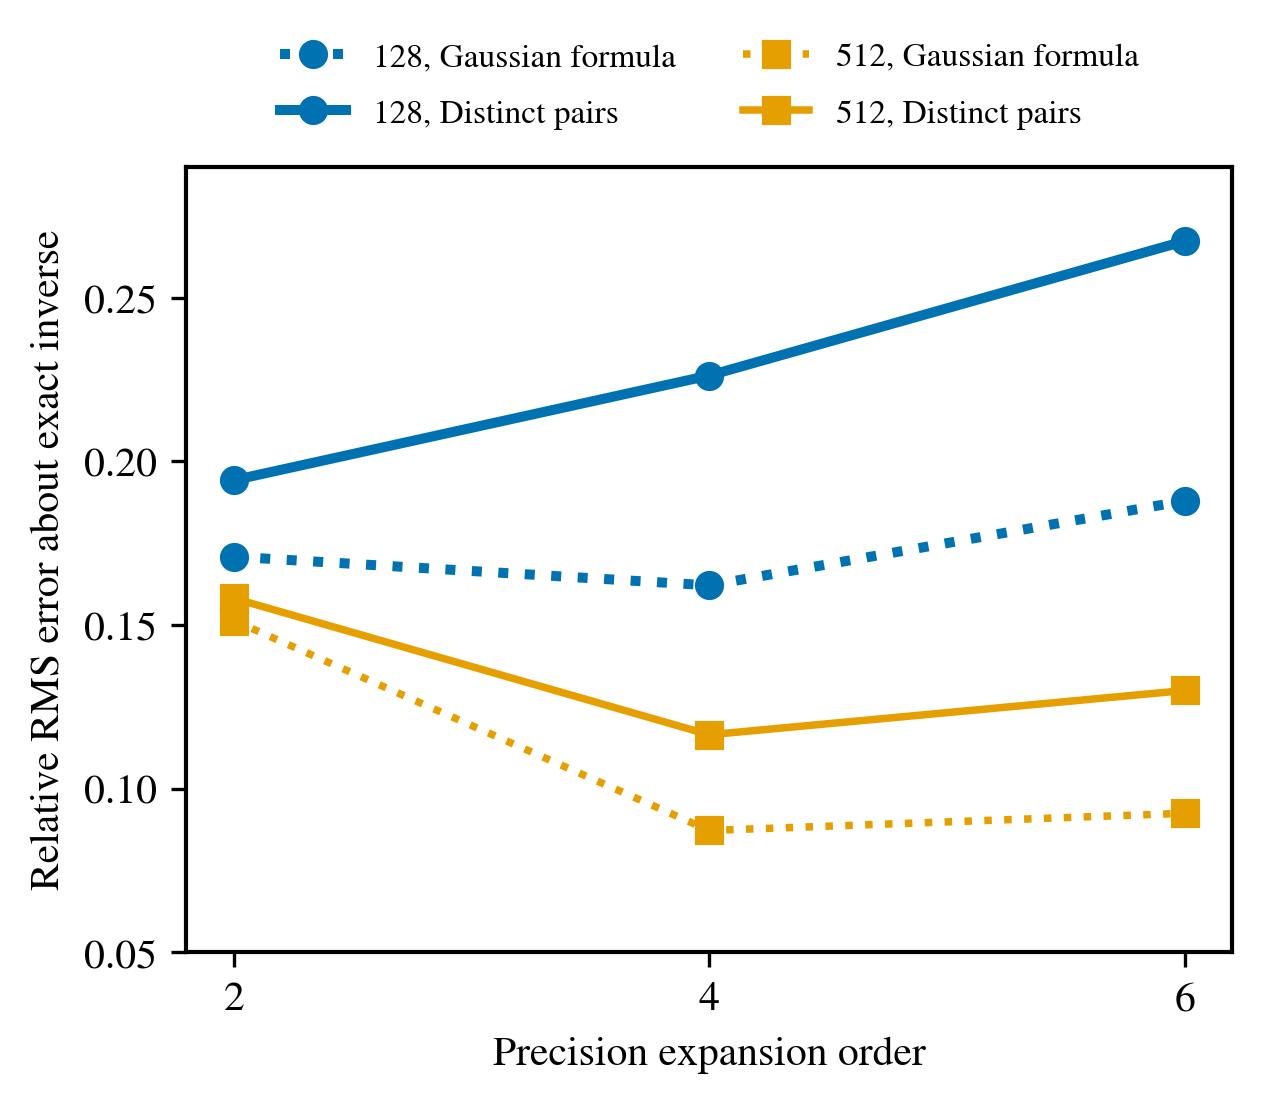

In [8]:
population = np.loadtxt(fname=RECORDS / 'measurement_population.txt')[:, [0,6,8,14]]
# Fix the unit conversion using the stipulated full population.
standardized = (population-population.mean(axis=0))/population.std(axis=0)
true_covariance = standardized.T @ standardized / len(standardized)
print('Exactly defined discrete-population covariance:')
print(true_covariance)
summary = np.loadtxt(fname=RECORDS / 'gptg_empirical_summary.txt')
# Column 4 is relative RMS error about the exact inverse. Column 3
# instead measures error about the finite polynomial target.
for count in (128,512):
    selected = summary[(summary[:,0] == count) & (summary[:,1] >= 3)]
    print(count, 'draws, distinct-pair RMS at orders 2,4,6:', selected[:,4])
display(Image(filename=str(NOTE / 'plots/precision/precision.png'), width=650))

More draws reduce scatter. In this experiment, 512 draws make fourth order useful, but sixth order still has higher RMS error. This is evidence against choosing the largest available order by default. Neither resampling nor an arbitrarily large generator ensemble removes uncertainty or missing physics in the calibration.

## 8. Run the actual programs, explicitly

Install `ducc0==0.42.0` and `astropy-healpix==1.0.3` in the selected Cocoa environment if needed; NumPy, SciPy, Astropy and PyYAML are also required. These commands are separate operations:

```bash
python -m pip install ducc0==0.42.0
```

```bash
python -m pip install astropy-healpix==1.0.3
```

From the activated Cocoa root, fit the selected 32 maps:

```bash
python projects/des_3pcf/notes/gptg_simulations/generate_maps.py fit --runs 32 --workers 4
```

Generate the 64-map pilot:

```bash
python projects/des_3pcf/notes/gptg_simulations/generate_maps.py generate --count 64 --workers 4
```

Existing generated files are not overwritten. Preserve or move a prior experiment before deliberately rerunning into the same destination. The first saved fit is an initial approximation, not an author-supplied calibration. Then compare and measure:

```bash
python projects/des_3pcf/notes/gptg_simulations/compare_maps.py
```

```bash
python projects/des_3pcf/notes/gptg_simulations/measure_apertures.py
```

The following switches are false by default because running this teaching notebook should not regenerate maps or repeat thousands of experiments silently. The numerical check does not need the full map archive, but does use the saved fit and footprint index file.

In [9]:
import subprocess
import sys

RUN_NUMERICAL_CHECKS = False
RUN_PRECISION_EXPERIMENT = False

if RUN_NUMERICAL_CHECKS:
    subprocess.run(
        args=[sys.executable, str(NOTE / 'check_numerics.py')],
        check=True,
        cwd=PROJECT,
    )
if RUN_PRECISION_EXPERIMENT:
    subprocess.run(
        args=[sys.executable, str(NOTE / 'map_precision_tests.py')],
        check=True,
        cwd=PROJECT,
    )
print((RECORDS / 'numerical_checks.txt').read_text())

Normalization 160 -> 240 nodes, weighted RMS: 7.033751977914459e-12
Hermite 64 versus direct 2D quadrature: 5.8718585549399904e-12
Hermite 64 -> 96, maximum correlation change: 4.4719783431901305e-13
Band-limited scalar harmonic round trip: 4.87017864611109e-12
Distinct-pair recurrence agrees with every subset through degree 6.
Noise-subtracted square and cube recover 0.039999999999999744 0.00799999999999984



## 9. What to improve before using thousands of additional mocks

The immediate physical work is a forward calibration of the masked power and reconstructed distributions, a checked noise/weight model, confirmation of shear conventions, convergence with harmonic range, and measurement of the intended published estimator. The existing coarse aperture comparisons are useful diagnostics, not that final matching. Parameter uncertainty in the fitted generator also matters: infinitely many draws from an uncertain model do not yield infinitely precise knowledge of the N-body covariance.

The separate [precision-expansion note](../covariance_from_simulations/covariance_from_simulations.pdf) contains the full second-to-sixth-order algebra and Gaussian/lognormal tests. The [Rafael comparison](../covariance_comparison/covariance_comparison.pdf) compares the same complete supplied ensemble with the same complete ensemble, and separately examines matched released DES bins.

## 10. Float32 files and independent validation

The 64-map rounding test compares float32 storage with float64 storage while keeping arithmetic in float64. New ensemble files use float32 (about 177 GB for 15,000 maps). The small original pilot remains float64 as a precision reference.

The larger run has **10,000 comparison maps plus 5,000 new validation maps**. It is still running; the cells below do not claim its results. All comparison maps enter both the direct and Eifler estimates. Validation does not choose the reference or expansion order.

For a fixed positive precision, use the score

$$J(\Psi)=\operatorname{tr}(\Psi C_*)-\log\det\Psi.$$

Its expectation is minimized at the true inverse covariance even for non-Gaussian vectors with finite covariance. The note proves this by diagonalizing $C_*^{1/2}\Psi C_*^{1/2}$. On independent validation data, replace $C_*$ by its unbiased sample covariance **without inverting it**. Score differences therefore do not require the direct inverse to be truth. The next small known-covariance example checks the target numerically.

In [10]:
print((RECORDS / 'float32_storage_check.txt').read_text())
true_covariance = np.array([[2., .3], [.3, 1.]])
true_precision = np.linalg.solve(a=true_covariance, b=np.eye(2))
true_score = np.trace(true_precision @ true_covariance)
true_score -= np.linalg.slogdet(true_precision)[1]
for factor in (0.5, 1., 1.5):
    candidate = factor*true_precision
    score = np.trace(candidate @ true_covariance)
    score -= np.linalg.slogdet(candidate)[1]
    expected_difference = 2*(factor-1.-np.log(factor))
    np.testing.assert_allclose(score-true_score, expected_difference, atol=1.e-14)
    print('Precision multiplier, excess expected score:', factor, score-true_score)
print('The minimum occurs at the known true precision in this worked example.')

max_absolute_shear_rounding 8.57983639690473865e-09
max_moment_change_in_its_single_map_standard_deviation 1.19411115907004286e-07
max_joint_covariance_weighted_vector_change 2.56353941029503208e-07
max_fractional_variance_change 1.49890324596668734e-08
max_relative_covariance_eigendirection_change 5.25167417506345957e-08
max_relative_precision_eigendirection_change 5.25167390685865598e-08

Precision multiplier, excess expected score: 0.5 0.3862943611198908
Precision multiplier, excess expected score: 1.0 0.0
Precision multiplier, excess expected score: 1.5 0.18906978378367123
The minimum occurs at the known true precision in this worked example.
